# Equivalent layer that crosses the sources

This code illustrates ...

### Things we have to import

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from gravmag import eqlayer, filters, transforms, convolve, utils, inverse_distance, data_structures
from gravmag.models import rectangular_prism as rp
from gravmag import plot_functions as plf
from gravmag import constants as cts

In [2]:
from scipy.fft import fftshift

In [3]:
from scipy.special import gammainc, gamma

### Points were we compute the synthetic data

In [4]:
# number of points along x and y
shape = (100,100)

# minimum x, maximum x, minimum y and maximum y
area = [-5000, 5000, -4000, 6000]

# coordinates 
xp = np.linspace(area[0], area[1], shape[0])
yp = np.linspace(area[2], area[3], shape[1])
yp, xp = np.meshgrid(yp, xp)

yp = np.ravel(yp)
xp = np.ravel(xp)

# constant vertical coordinate of the simulated gravity data
z_data = -150

zp = np.zeros_like(yp) + z_data

In [5]:
# full grid of coordinates required by computing the 
# potential field due to rectangular prisms. The necessity of a full grid
# should be dropped in future implementations.
coordinates = {
    'x': xp, 
    'y': yp, 
    'z': zp
}

coordinates_grid = data_structures.regular_grid_xy(
    area=area,
    shape=shape,
    z0=z_data,
    ordering='xy'
)

In [6]:
# Grid spacing
dx = (area[1] - area[0])/(shape[0]-1)
dy = (area[3] - area[2])/(shape[1]-1)

In [7]:
print(dx, dy)

101.01010101010101 101.01010101010101


In [8]:
N_data = np.prod(shape)

### Main model

In [9]:
# Create a main model formed by a single prism
model_main = {
    'x1': np.array([-3000]),
    'x2': np.array([2800]),
    'y1': np.array([0]),
    'y2': np.array([2000]),
    'z1': np.array([150]),
    'z2': np.array([1010])
}

density_main = np.array([2000]) # 2000 kg/m³ = 2 g/cm³

In [10]:
# scaled total mass of the main model
Omega_main = 2*np.pi*cts.GRAVITATIONAL_CONST*np.sum(density_main*utils.prisms_volume(model_main))

### Geological noise model

In [11]:
# center of Ns sources randomly distributed in the simulated area
Ngn = 300

xgn = area[0] + (area[1] - area[0])*np.random.rand(Ngn)
ygn = area[2] + (area[3] - area[2])*np.random.rand(Ngn)
zgn_top = z_data + 100. + 100.*np.random.rand(Ngn)

# sizes 
Lgn = 100. + 200*np.random.rand(Ngn)

# densities
density_gn = 2000. + 3000.*np.random.rand(Ngn)

# create the sources
model_gn = {
    'x1': xgn - 0.5*Lgn,
    'x2': xgn + 0.5*Lgn,
    'y1': ygn - 0.5*Lgn,
    'y2': ygn + 0.5*Lgn,
    'z1': np.zeros(Ngn) + np.min(zgn_top),
    'z2': zgn_top + Lgn
}

In [12]:
# scaled total mass of the geological noise model
Omega_gn = 2*np.pi*cts.GRAVITATIONAL_CONST*np.sum(density_gn*utils.prisms_volume(model_gn))

In [13]:
Omega = Omega_main + Omega_gn

### Synthetic gravitational field

In [14]:
U_main = rp.grav(coordinates=coordinates, prisms=model_main, density=density_main, field='potential')

In [15]:
U_gn = rp.grav(coordinates=coordinates, prisms=model_gn, density=density_gn, field='potential')

In [16]:
U = U_main + U_gn

In [17]:
gz_main = rp.grav(coordinates=coordinates, prisms=model_main, density=density_main, field='z')

In [18]:
gz_gn = rp.grav(coordinates=coordinates, prisms=model_gn, density=density_gn, field='z')

In [19]:
gz = gz_main + gz_gn

In [20]:
bounds = np.max(np.abs([gz_main, gz_gn, gz]))

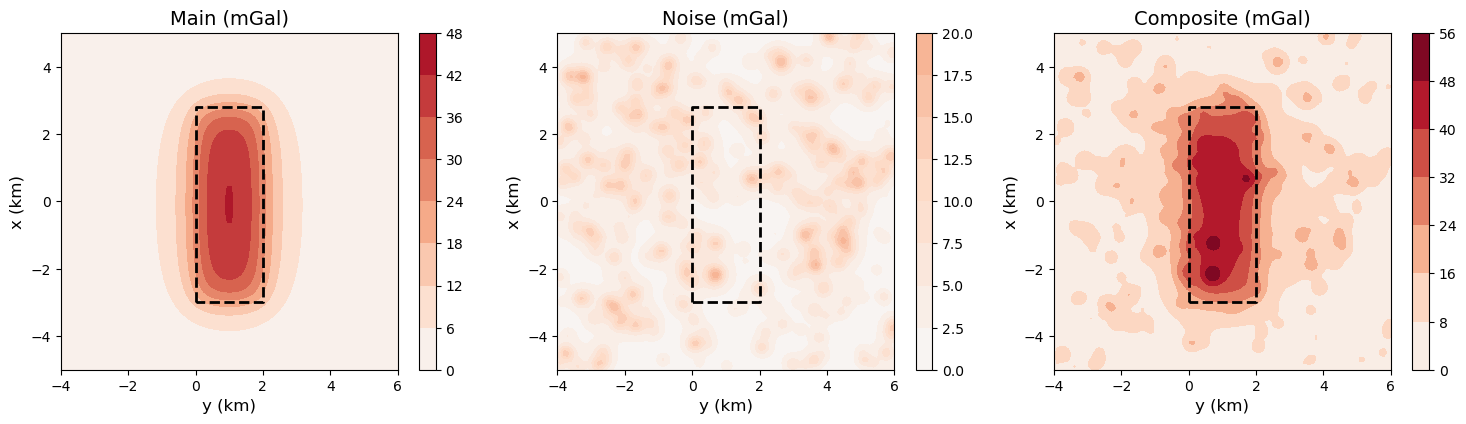

In [21]:
fields = [gz_main, gz_gn, gz]

titles = ['Main (mGal)', 'Noise (mGal)', 'Composite (mGal)']

windows = [i for i in range(1,4)]

plt.figure(figsize=(15,4))

for w, window in enumerate(windows):

    plt.subplot(1,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        yp.reshape(shape)*0.001, 
        xp.reshape(shape)*0.001, 
        fields[w].reshape(shape), 
        cmap='RdBu_r',
        vmin = -bounds, vmax = bounds
    )
    plt.colorbar()
    plf.model_boundaries(model_main, m2km=True)
    plt.ylim(0.001*area[0], 0.001*area[1])
    plt.xlim(0.001*area[2], 0.001*area[3])
    plt.xlabel('y (km)', fontsize=12)
    plt.ylabel('x (km)', fontsize=12)

plt.tight_layout()

plt.show()

### Comparison $\Omega$ and numerically obtained total mass

In [22]:
Omega_numerical = dx*dy*np.sum(gz)/cts.SI2MGAL

In [23]:
Omega_numerical

12135.36636344705

In [24]:
Omega

13985.172091762066

In [25]:
Omega_numerical/Omega

0.8677309284306455

### Theoretical equivalent layer

In [26]:
# compute 2D Fourier transform of U without padding
FT_gz = transforms.DFT(data=gz.reshape(shape))

In [27]:
# multiply FT_gz by the element of area to retrieve the true Fourier Transform amplitude
FT_gz *= dx*dy

# set the FT_gz equal to zero at the zero frequency
FT_gz[0,0] = 0.

In [28]:
# compute wavenumbers
kx, ky, kz = filters.wavenumbers(FT_gz.shape, dx, dy)

In [29]:
# set the equivalent layer depth
z_layer = 300.

In [30]:
# define the continuation filter
down_continuation_filter = [filters.continuation(kz=kz, dz=z_layer-z_data)]

In [ ]:
# compute the downward continued field on the layer
FT_gz_downward_layer = convolve.compute(FT_gz, down_continuation_filter)

In [ ]:
bounds = [
    np.max(np.abs(FT_gz)), 
    np.max(np.abs(FT_gz_downward_layer))
]

fields = [np.abs(FT_gz), np.abs(FT_gz_downward_layer)]

titles = ['Spectrum gz', 'Spectrum continued gz']

windows = [i for i in range(1,3)]

plt.figure(figsize=(10,4))

for w, window in enumerate(windows):

    plt.subplot(1,2,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        fftshift(ky), 
        fftshift(kx), 
        fftshift(fields[w]), 
        cmap='RdBu_r',
        vmin = -bounds[w], vmax = bounds[w]
    )
    plt.colorbar()
    plt.ylim(kx.min(), kx.max())
    plt.xlim(ky.min(), ky.max())
    plt.xlabel('ky', fontsize=12)
    plt.ylabel('kx', fontsize=12)

plt.tight_layout()

plt.show()

In [ ]:
# cuttoff wavenumber
kz_epsilon = np.linspace(0.001, 0.02, 30)

In [ ]:
# Distance from top of the sources and the observation plane
z_model_top = min(np.min(model_main['z1']), np.min(model_gn['z1']))
Dz = z_model_top - z_data

In [ ]:
z_model_top

In [ ]:
epsilon = []
for kz_epsilon_i in kz_epsilon:
    a = 1e-7
    #epsilon.append(gammaincc(a, 2*Dz*kz_epsilon_i)*gamma(a))
    #epsilon.append(gammaincc(a, kz_epsilon_i))
    epsilon.append(gamma(a)*(1. - gammainc(a, 2*Dz*kz_epsilon_i)))
epsilon = np.array(epsilon)*(2*np.pi*(Omega)**2)/(dx*dy*N_data)

In [ ]:
epsilon

In [ ]:
# compute 2D Fourier transform of gz with padding
FT_gz = transforms.DFT(data=gz.reshape(shape), pad_mode='linear_ramp')

# compute wavenumbers
kx, ky, kz = filters.wavenumbers(FT_gz.shape, dx, dy)

In [ ]:
plt.figure()
plt.plot(kz.ravel(), np.abs(FT_gz).ravel(), 'k.')
plt.show()

In [ ]:
# define the continuation filter
down_continuation_filter = filters.continuation(kz=kz, dz=z_layer-z_data)

In [ ]:
gz_downward_layer = []
for kz_epsilon_i in kz_epsilon:
    # define the composite filter
    composite_filter = [
        filters.cuttof_frequency(kz, kz_epsilon_i),
        down_continuation_filter
    ]
    # compute the downward continued field in Fourier domain
    FT_gz_downward_layer = convolve.compute(FT_gz, composite_filter)
    # transform the downward continued field to space domain
    gz_downward_layer.append(transforms.IDFT(FT_gz_downward_layer, unpad=True, grid=False))

In [ ]:
# theoretical equivalent layer
p_theoretical = []
for gz_down_i in gz_downward_layer:
    p_theoretical.append(((dx*dy)/(2*np.pi*cts.SI2MGAL))*gz_down_i)

In [ ]:
# set the equivalent layer depth
z_layer = 300.

# compute the Squared Euclidean Distance Matrix (SEDM)
R2 = inverse_distance.sedm_BTTB(
    data_grid=coordinates_grid,
    delta_z=z_layer-z_data
)

# kernel matrix associated with the equivalent layer
G = inverse_distance.grad_BTTB(
    data_grid=coordinates_grid,
    delta_z=z_layer-z_data,
    SEDM=R2,
    components=["z"]
)

In [ ]:
# list for storing the predicted gravitational field components
predicted_fields = []
for p_theoretical_i in p_theoretical:
    # compute the predicted field and update the list
    predicted_fields.append(G@p_theoretical_i)

In [ ]:
error = []
for predicted_field in predicted_fields:
    residuals = predicted_field - U
    error.append(np.sum(residuals*residuals))
error = np.array(error)

In [ ]:
error

In [ ]:
np.argmin(error)

In [ ]:
epsilon

In [ ]:
plt.figure()
plt.plot(kz_epsilon, error, 'k--', label='error')
#plt.plot(kz_epsilon, epsilon, 'k-', label = '$\\varepsilon$')
plt.xlabel('$k_{\\varepsilon}$', fontsize=14)
plt.ylabel('$\\varepsilon$', fontsize=14)
plt.grid()
plt.legend(loc='best')
plt.show()

In [ ]:
U_bounds = np.max(np.abs([U, predicted_fields[np.argmin(error)]]))
diff_bounds = np.max(np.abs(predicted_fields[np.argmin(error)] - U))
bounds = [U_bounds, U_bounds, diff_bounds]

fields = [predicted_fields[np.argmin(error)], U, predicted_fields[np.argmin(error)] - U]

titles = ['Predicted (m²/s²)', 'True (m²/s²)', 'Difference (m²/s²)']

windows = [i for i in range(1,4)]

plt.figure(figsize=(15,4))

for w, window in enumerate(windows):

    plt.subplot(1,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        yp.reshape(shape)*0.001, 
        xp.reshape(shape)*0.001, 
        fields[w].reshape(shape), 
        cmap='RdBu_r',
        vmin = -bounds[w], vmax = bounds[w]
    )
    plt.colorbar()
    plf.model_boundaries(model_main, m2km=True)
    plt.ylim(0.001*area[0], 0.001*area[1])
    plt.xlim(0.001*area[2], 0.001*area[3])
    plt.xlabel('y (km)', fontsize=12)
    plt.ylabel('x (km)', fontsize=12)

plt.tight_layout()

plt.show()